# Pipeline Preditivo de Risco de Crédito (Opção A)

**Disciplina:** Machine Learning e Visão Computacional - Projeto Avaliativo (SENAI/SC)  
**Objetivo de Negócio:** Prever a probabilidade de inadimplência de solicitantes de empréstimo (`loan_status = 1`) versus bons pagadores (`loan_status = 0`), equilibrando prevenção a calotes e aprovação de bons clientes.

Este notebook organiza o pipeline completo em **6 fases técnicas**, reutilizando os módulos Python da pasta `src/` para manter o código limpo, reprodutível e livre de vazamento de dados (*Data Leakage*).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import CONTINUOUS_COLS, DEFAULT_LGD, FEATURE_ENGINEERED_COL, FIGURES_DIR, TARGET_COL
from src.data_prep import clean_data, eda_summary, engineer_features, load_dataset
from src.modeling import (
    build_final_evaluation,
    compare_balancing_methods,
    evaluate_knn_grid,
    evaluate_thresholds,
    evaluate_tree_grid,
    extract_feature_importance,
    select_best_model,
)
from src.plots import (
    plot_confusion_matrices,
    plot_correlation_heatmap,
    plot_eda_distributions,
    plot_feature_importance,
    plot_outliers_comparison,
    plot_overfitting_curves,
    plot_roc_and_threshold,
    plot_target_imbalance,
)
from src.preprocessing import encode_features, split_balance_and_scale

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("Ambiente carregado com sucesso.")

Ambiente carregado com sucesso.


---
## Fase 1: Análise Exploratória de Dados (EDA)

Primeiro verificamos o tamanho da base, tipos das colunas, resumo estatístico, registros duplicados, valores ausentes, assimetria (*skewness*), desbalanceamento da variável alvo (`loan_status`) e correlação de Pearson.

In [2]:
df_raw = load_dataset()
eda = eda_summary(df_raw)

print(f"Dimensão da base bruta: {eda['shape'][0]:,} linhas x {eda['shape'][1]} colunas")
print(f"Linhas duplicadas exatas: {eda['duplicates']}")

print("\n--- Tipos de Dados e Valores Ausentes ---")
info_df = pd.DataFrame({
    "dtype": eda["dtypes"].astype(str),
    "nulos": eda["null_counts"],
    "nulos_%": eda["null_pct"],
})
display(info_df)

print("\n--- Sumário Estatístico Descritivo (.describe()) ---")
display(eda["describe"])

print("\n--- Assimetria (Skewness) das Variáveis Numéricas ---")
display(eda["skewness"].to_frame(name="skewness"))

print("\n--- Distribuição da Variável Alvo (loan_status) ---")
display(pd.DataFrame({"contagem": eda["target_counts"], "percentual_%": eda["target_pct"]}))

Dimensão da base bruta: 32,581 linhas x 12 colunas
Linhas duplicadas exatas: 165

--- Tipos de Dados e Valores Ausentes ---


,dtype,nulos,nulos_%
person_age,int64,0,0.0000
person_income,int64,0,0.0000
person_home_ownership,str,0,0.0000
person_emp_length,float64,895,2.7500
loan_intent,str,0,0.0000
loan_grade,str,0,0.0000
loan_amnt,int64,0,0.0000
loan_int_rate,float64,3116,9.5600
loan_status,int64,0,0.0000
loan_percent_income,float64,0,0.0000



--- Sumário Estatístico Descritivo (.describe()) ---


,count,mean,std,min,25%,50%,75%,max
person_age,"32,581.0000",27.7346,6.3481,20.0000,23.0000,26.0000,30.0000,144.0000
person_income,"32,581.0000","66,074.8485","61,983.1192","4,000.0000","38,500.0000","55,000.0000","79,200.0000","6,000,000.0000"
person_emp_length,"31,686.0000",4.7897,4.1426,0.0000,2.0000,4.0000,7.0000,123.0000
loan_amnt,"32,581.0000","9,589.3711","6,322.0866",500.0000,"5,000.0000","8,000.0000","12,200.0000","35,000.0000"
loan_int_rate,"29,465.0000",11.0117,3.2405,5.4200,7.9000,10.9900,13.4700,23.2200
loan_status,"32,581.0000",0.2182,0.4130,0.0000,0.0000,0.0000,0.0000,1.0000
loan_percent_income,"32,581.0000",0.1702,0.1068,0.0000,0.0900,0.1500,0.2300,0.8300
cb_person_cred_hist_length,"32,581.0000",5.8042,4.0550,2.0000,3.0000,4.0000,8.0000,30.0000



--- Assimetria (Skewness) das Variáveis Numéricas ---


,skewness
person_age,2.5810
person_income,32.8650
person_emp_length,2.6140
loan_amnt,1.1920
loan_int_rate,0.2090
loan_status,1.3650
loan_percent_income,1.0650
cb_person_cred_hist_length,1.6620



--- Distribuição da Variável Alvo (loan_status) ---


,contagem,percentual_%
loan_status,,
0,25473,78.1800
1,7108,21.8200


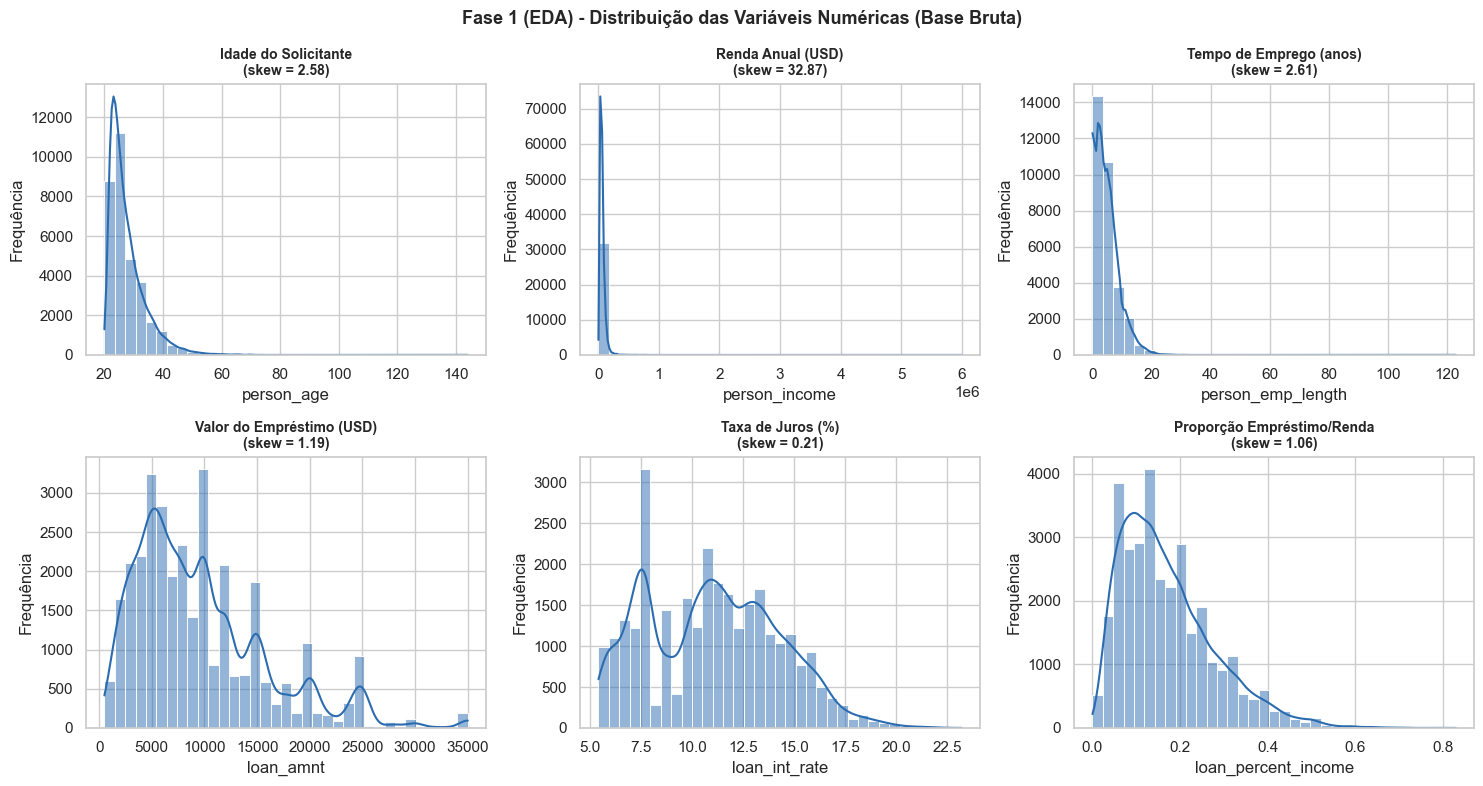

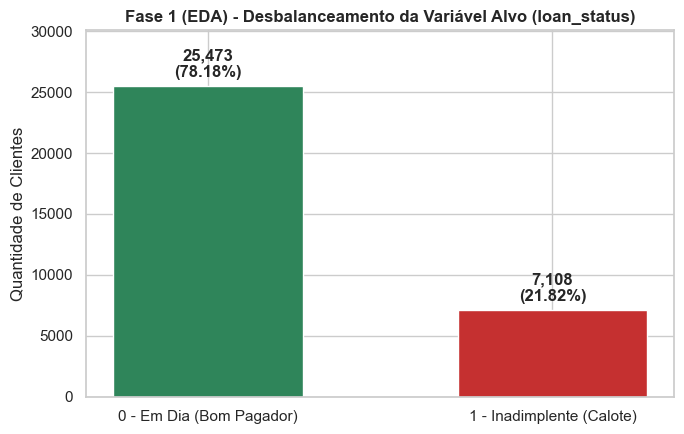

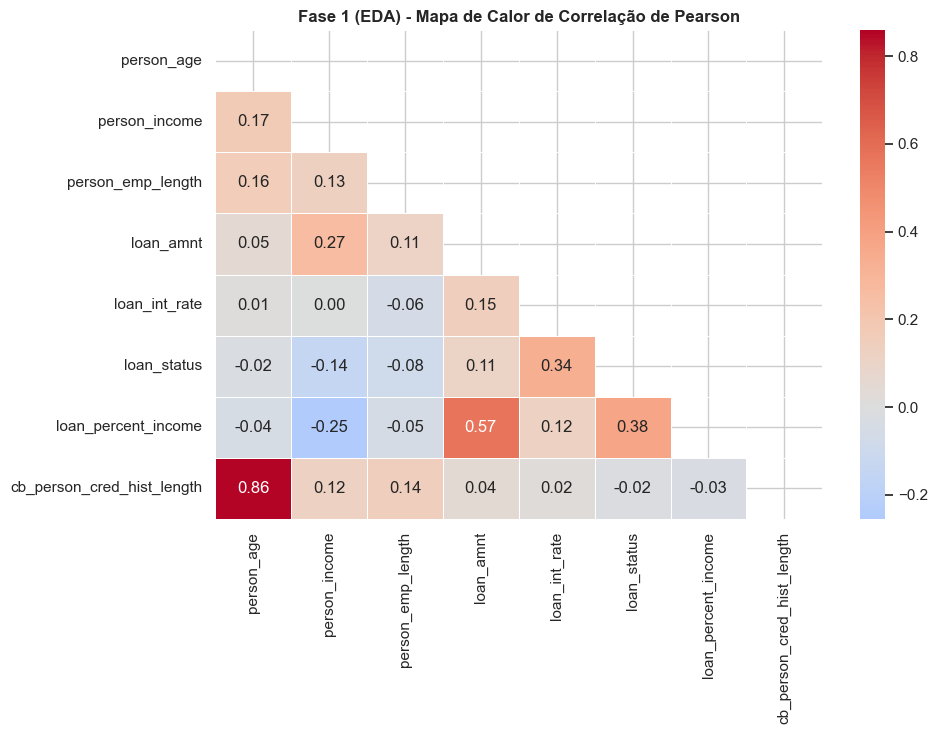

In [3]:
fig1 = plot_eda_distributions(df_raw, FIGURES_DIR / "01_eda_distribuicoes.png")
plt.show()

fig2 = plot_target_imbalance(df_raw, FIGURES_DIR / "02_eda_desbalanceamento_alvo.png")
plt.show()

fig3 = plot_correlation_heatmap(df_raw, FIGURES_DIR / "03_eda_correlacao_pearson.png")
plt.show()

### Tomada de Decisão (Interpretação da EDA)

A partir das estatísticas e dos gráficos, quatro pontos guiam o tratamento dos dados:

1. **Desbalanceamento da variável alvo**: `78,18%` dos registros são bons pagadores (`loan_status = 0`) e `21,82%` são inadimplentes (`loan_status = 1`), proporção de cerca de **3,6 para 1**. Olhar apenas acurácia esconderia falhas na classe minoritária; por isso faremos divisão estratificada (`stratify=y`), balanceamento apenas no treino (comparando **RandomUnderSampler** vs **SMOTE** em validação cruzada 5-Fold) e avaliação focada em **F1-Score, Recall e Precisão**.
2. **Erros de cadastro e valores extremos**: há idades impossíveis de até **144 anos** (5 casos acima de 100 anos), tempos de emprego de **123 anos** (maiores que a idade do cliente) e renda anual chegando a **US\$ 6.000.000** (`skew = 32,87`). Esses valores precisam ser corrigidos antes do treino, principalmente porque distorcem o cálculo de distância do KNN.
3. **Nulos com comportamentos diferentes**: apenas `person_emp_length` (`2,75%` nulos, `skew = 2,61`, forte assimetria à direita) e `loan_int_rate` (`9,56%` nulos, `skew = 0,21`, distribuição bem próxima de simétrica) possuem valores ausentes. Isso pede técnicas de imputação diferentes (Mediana vs Média).
4. **Sinais de correlação**: no mapa de calor de Pearson, `loan_percent_income` (`+0,38`) e `loan_int_rate` (`+0,34`) têm a maior correlação positiva com inadimplência, enquanto `person_income` (`-0,14`) tem relação inversa, reforçando o peso da variável `comprometimento_renda` criada na Fase 3.

---
## Fase 2: Tratamento e Limpeza (Data Prep)

### Justificativa das Decisões

1. **Remoção de Duplicadas**: removemos `165` linhas idênticas para evitar redundância e impedir que um mesmo registro apareça no treino e no teste.
2. **Tratamento de Outliers (impacto no KNN vs Árvore de Decisão)**:
   - **Remoção de anomalias impossíveis**: descartamos os `5` registros com `person_age > 100` (`123` e `144` anos, o que já elimina o caso de renda de US\$ 6 milhões) e os `2` registros com `person_emp_length > 60` (`123` anos de emprego em clientes de 21 e 22 anos). No total são apenas `7` linhas (`0,02%` da base).
   - **Clipping no P99 (`US\$ 225.000`) para `person_income`**: os `322` clientes acima do percentil 99 (até US\$ 2,04M) continuam na base, mas limitados ao teto de P99. O **KNN** usa distância euclidiana e `StandardScaler`, então rendas extremas inflam o desvio-padrão e espremem quase todos os demais clientes num intervalo pequeno, prejudicando os vizinhos mais próximos. Já a **Árvore de Decisão** não sofre com outliers porque trabalha com cortes por ordem de valor.
3. **Imputação de Valores Nulos (Média vs Mediana)**:
   - **`person_emp_length` (Mediana = `4,0` anos)**: distribuição assimétrica à direita (`skew > 1`) e afetada por valores altos; a mediana evita puxar a estimativa para cima.
   - **`loan_int_rate` (Média = `11,02%`)**: distribuição quase simétrica (`skew = 0,21`, com média `11,02%` muito próxima da mediana `10,99%`), tornando a média adequada.

--- Relatório de Limpeza (Fase 2) ---


,valor
initial_rows,"32,581.0000"
duplicates_removed,165.0000
invalid_age_removed,5.0000
invalid_emp_removed,2.0000
income_cap_p99,"225,000.0000"
income_clipped_count,322.0000
emp_length_nulls_imputed,887.0000
emp_length_median,4.0000
int_rate_nulls_imputed,"3,094.0000"
int_rate_mean,11.0171


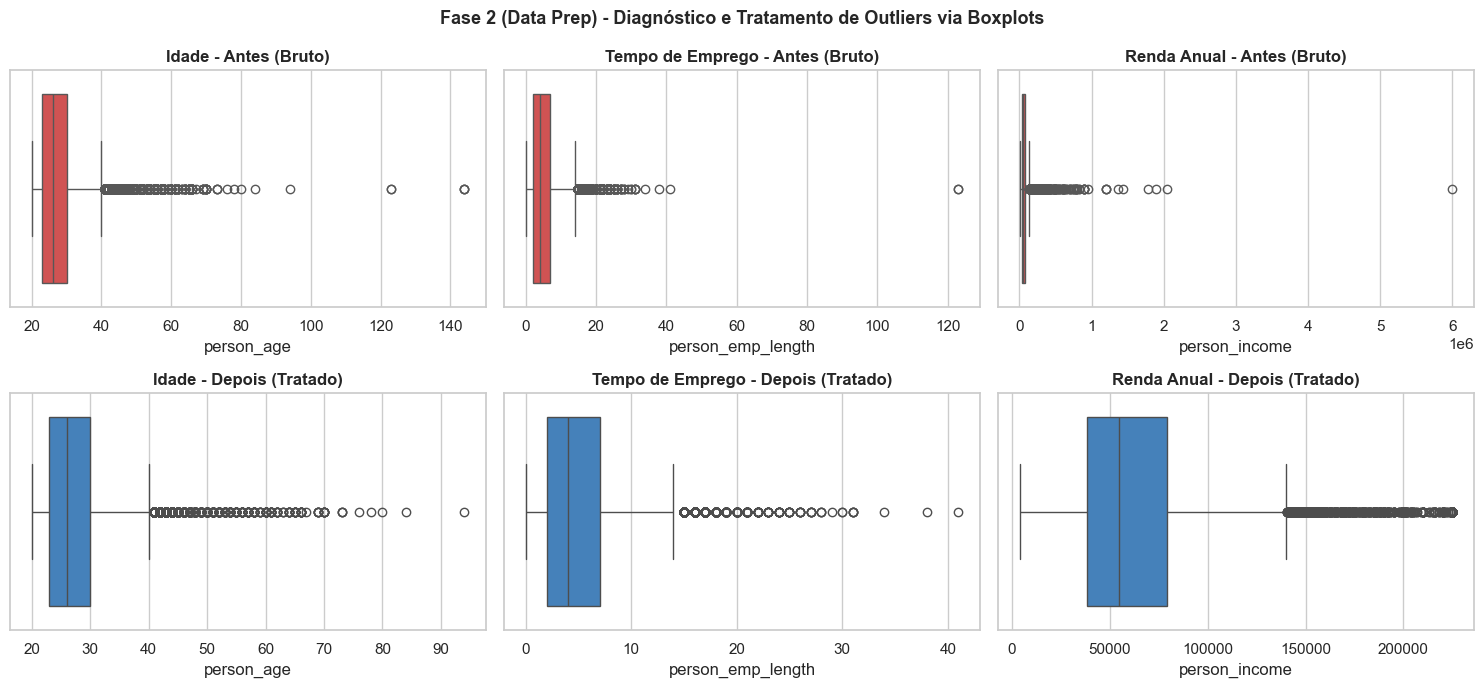

In [4]:
df_clean, clean_report = clean_data(df_raw)

print("--- Relatório de Limpeza (Fase 2) ---")
display(pd.Series(clean_report, name="valor").to_frame())

fig4 = plot_outliers_comparison(df_raw, df_clean, FIGURES_DIR / "04_outliers_boxplots.png")
plt.show()

---
## Fase 3: Feature Engineering (Coluna Calculada)

Criamos a coluna exigida `comprometimento_renda = (loan_amnt / person_income) * 100`, indicando em percentual quanto o valor do empréstimo representa sobre a renda anual do cliente.

O cálculo roda **depois** da Fase 2 (sem nulos nas colunas originais) e com checagem de `person_income > 0` para impedir qualquer `NaN` ou infinito (`inf`).

In [5]:
df_feat = engineer_features(df_clean)

print(f"Nulos em {FEATURE_ENGINEERED_COL}: {df_feat[FEATURE_ENGINEERED_COL].isna().sum()}")
print(f"Infinitos em {FEATURE_ENGINEERED_COL}: {(~np.isfinite(df_feat[FEATURE_ENGINEERED_COL])).sum()}")
display(df_feat[["loan_amnt", "person_income", "loan_percent_income", FEATURE_ENGINEERED_COL]].describe().T)

corr_new = df_feat[FEATURE_ENGINEERED_COL].corr(df_feat[TARGET_COL])
print(f"Correlação de Pearson ({FEATURE_ENGINEERED_COL} vs {TARGET_COL}): {corr_new:.4f}")

Nulos em comprometimento_renda: 0
Infinitos em comprometimento_renda: 0


,count,mean,std,min,25%,50%,75%,max
loan_amnt,"32,409.0000","9,592.4867","6,320.8851",500.0000,"5,000.0000","8,000.0000","12,250.0000","35,000.0000"
person_income,"32,409.0000","64,335.4264","37,769.5467","4,000.0000","38,500.0000","55,000.0000","79,200.0000","225,000.0000"
loan_percent_income,"32,409.0000",0.1702,0.1068,0.0000,0.0900,0.1500,0.2300,0.8300
comprometimento_renda,"32,409.0000",17.0806,10.6873,0.4444,9.0000,14.8368,22.9167,83.0000


Correlação de Pearson (comprometimento_renda vs loan_status): 0.3863


---
## Fase 4: Separação, Balanceamento e Escalonamento Seguro

### Decisões de Preparação (Sem Vazamento de Dados)

1. **Encoding de Variáveis Categóricas**:
   - `cb_person_default_on_file`: binário (`N = 0`, `Y = 1`).
   - `loan_grade`: ordinal (`A = 0` até `G = 6`), preservando a ordem real de risco de crédito.
   - `person_home_ownership` e `loan_intent`: **One-Hot Encoding** (`drop_first=True`), pois são categorias nominais sem ordem numérica.
2. **Split Estratificado (`80%` Treino / `20%` Teste)**: `train_test_split(..., test_size=0.20, stratify=y, random_state=42)` preservando a proporção original de inadimplentes (`~21,88%`) no conjunto de teste.
3. **Escolha do Balanceamento via Validação Cruzada 5-Fold (Anti-Leakage)**:
   - Comparamos **RandomUnderSampler** vs **SMOTE** executando balanceamento e `StandardScaler` apenas dentro de cada fold de treino.
   - Como há colunas One-Hot binárias misturadas às contínuas, o **SMOTE** interpola registros sintéticos entre categorias e aumenta a variação entre folds. O **RandomUnderSampler** usa **100% clientes reais** (`5.670` bons pagadores e `5.670` inadimplentes = `11.340` registros no treino), alcançando F1 mais alto e menor desvio padrão nos dois modelos. O teste (`6.482` registros) permanece intocado.
4. **Escalonamento Separado por Algoritmo**:
   - **KNN**: `StandardScaler` aplicado apenas nas **8 variáveis contínuas**, com `fit_transform` no treino balanceado e `transform` no teste.
   - **Árvore de Decisão**: treinada **sem escalonamento** (`X_train_tree`, `X_test_tree`), pois realiza cortes monotônicos independentes da escala dos dados.

In [6]:
df_enc = encode_features(df_feat)
bundle = split_balance_and_scale(df_enc, balancing_method="rus")

print(f"Colunas após encoding ({len(bundle['feature_names'])} features): {bundle['feature_names']}")

print("\n--- Comparação de Balanceamento (5-Fold CV Estratificado Anti-Leakage) ---")
cv_balancing_df = compare_balancing_methods(bundle["X_train_raw"], bundle["y_train_raw"])
display(cv_balancing_df)

print("\n--- Contagem de Classes (RandomUnderSampler Apenas no Treino) ---")
summary_split = pd.DataFrame({
    "Treino Bruto (80%)": bundle["y_train_raw"].value_counts().sort_index(),
    "Treino Balanceado RUS (50/50)": bundle["y_train_bal"].value_counts().sort_index(),
    "Teste Intacto (20%)": bundle["y_test"].value_counts().sort_index(),
})
display(summary_split)

print("\n--- Comprovação de Escalonamento (KNN escalonado vs Árvore em escala original) ---")
scale_check = pd.DataFrame({
    "KNN_treino_media": bundle["X_train_knn"][CONTINUOUS_COLS].mean().round(4),
    "KNN_treino_std": bundle["X_train_knn"][CONTINUOUS_COLS].std(ddof=0).round(4),
    "Arvore_treino_media": bundle["X_train_tree"][CONTINUOUS_COLS].mean().round(2),
    "Arvore_treino_std": bundle["X_train_tree"][CONTINUOUS_COLS].std(ddof=0).round(2),
})
display(scale_check)

Colunas após encoding (18 features): ['person_age', 'person_income', 'person_emp_length', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'comprometimento_renda', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE']

--- Comparação de Balanceamento (5-Fold CV Estratificado Anti-Leakage) ---


,metodo,codigo,tree_cv_f1_mean,tree_cv_f1_std,tree_cv_auc_mean,knn_cv_f1_mean,knn_cv_f1_std,knn_cv_auc_mean
0,RandomUnderSampler,rus,0.7863,0.0065,0.9060,0.6607,0.0037,0.8811
1,SMOTE,smote,0.7188,0.0363,0.8822,0.6493,0.0069,0.8692



--- Contagem de Classes (RandomUnderSampler Apenas no Treino) ---


,Treino Bruto (80%),Treino Balanceado RUS (50/50),Teste Intacto (20%)
loan_status,,,
0,20257,5670,5064
1,5670,5670,1418



--- Comprovação de Escalonamento (KNN escalonado vs Árvore em escala original) ---


,KNN_treino_media,KNN_treino_std,Arvore_treino_media,Arvore_treino_std
person_age,-0.0000,1.0000,27.6000,6.1800
person_income,0.0000,1.0000,"58,400.3800","36,080.5700"
person_emp_length,-0.0000,1.0000,4.5500,3.9300
loan_amnt,0.0000,1.0000,"10,039.9100","6,625.4800"
loan_int_rate,0.0000,1.0000,11.7000,3.2500
loan_percent_income,-0.0000,1.0000,0.2000,0.1200
cb_person_cred_hist_length,0.0000,1.0000,5.7200,4.0300
comprometimento_renda,0.0000,1.0000,19.9000,12.2100


---
## Fase 5: Modelagem e Validação (O Desafio do Overfitting)

Testamos **6 configurações** por algoritmo comparando **Treino e Teste** ao mesmo tempo:
- **KNN (dados escalonados)**: `n_neighbors` em `[3, 5, 7, 9, 11, 15]`.
- **Árvore de Decisão (dados sem escala)**: `max_depth` em `[3, 5, 7, 8, 10, None (Ilimitada)]`.

--- Grid KNN (Dados Escalonados) ---


,param_label,train_accuracy,test_accuracy,train_f1,test_f1,test_precision,test_recall,test_roc_auc,gap_f1
0,K=3,0.8930,0.8028,0.8913,0.6342,0.5337,0.7814,0.8573,0.2571
1,K=5,0.8668,0.8129,0.8636,0.6452,0.5512,0.7779,0.8753,0.2184
2,K=7,0.8541,0.8243,0.8505,0.6627,0.5712,0.7891,0.8853,0.1877
3,K=9,0.8466,0.8268,0.8426,0.6671,0.5754,0.7934,0.8881,0.1755
4,K=11,0.8418,0.8300,0.8375,0.6712,0.5817,0.7934,0.8928,0.1662
5,K=15,0.8317,0.8318,0.8269,0.6729,0.5857,0.7906,0.8927,0.1540



--- Grid Árvore de Decisão (Dados Sem Escalonamento) ---


,param_label,actual_depth,n_leaves,train_accuracy,test_accuracy,train_f1,test_f1,test_precision,test_recall,test_roc_auc,gap_f1
0,3,3,7,0.8305,0.8815,0.8134,0.7352,0.7193,0.7518,0.8569,0.0783
1,5,5,22,0.8439,0.8923,0.8297,0.7586,0.7442,0.7736,0.8962,0.0710
2,7,7,50,0.8521,0.9104,0.8344,0.7862,0.8222,0.7532,0.9112,0.0482
3,8,8,75,0.8605,0.9142,0.8433,0.7938,0.8372,0.7546,0.9143,0.0495
4,10,10,162,0.8778,0.9023,0.8653,0.7753,0.7806,0.7701,0.9175,0.0900
5,Ilimitada,30,1357,1.0000,0.8149,1.0000,0.6648,0.5504,0.8392,0.8236,0.3352


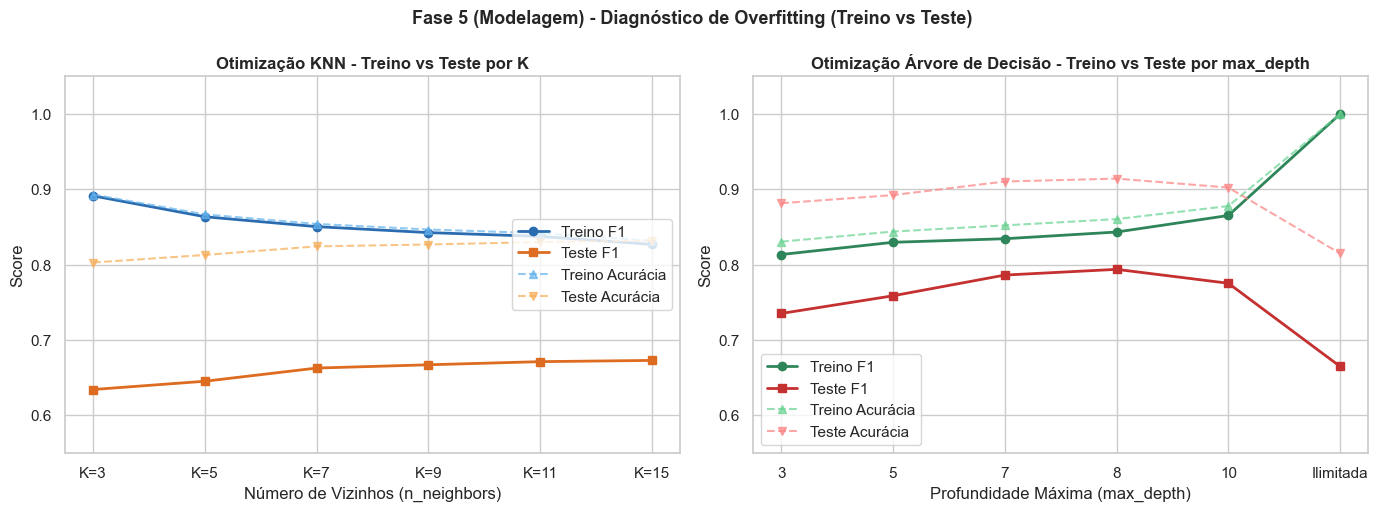

In [7]:
knn_df, knn_models = evaluate_knn_grid(
    bundle["X_train_knn"],
    bundle["y_train_bal"],
    bundle["X_test_knn"],
    bundle["y_test"],
)
tree_df, tree_models = evaluate_tree_grid(
    bundle["X_train_tree"],
    bundle["y_train_bal"],
    bundle["X_test_tree"],
    bundle["y_test"],
)

print("--- Grid KNN (Dados Escalonados) ---")
display(knn_df[["param_label", "train_accuracy", "test_accuracy", "train_f1", "test_f1", "test_precision", "test_recall", "test_roc_auc", "gap_f1"]])

print("\n--- Grid Árvore de Decisão (Dados Sem Escalonamento) ---")
display(tree_df[["param_label", "actual_depth", "n_leaves", "train_accuracy", "test_accuracy", "train_f1", "test_f1", "test_precision", "test_recall", "test_roc_auc", "gap_f1"]])

fig5 = plot_overfitting_curves(knn_df, tree_df, FIGURES_DIR / "05_overfitting_knn_vs_arvore.png")
plt.show()

### Diagnóstico de Overfitting

1. **KNN (`K = 3` até `15`)**:
   - Com **`K = 3`**, o modelo sofre *overfitting* local (`train_f1 = 0,8913` vs `test_f1 = 0,6342`, `gap_f1 = 0,2571`), gerando fronteiras muito sensíveis a ruído.
   - Aumentando `K`, o modelo generaliza melhor até atingir o melhor ponto em **`K = 15`** (`test_accuracy = 83,18%`, `test_f1 = 0,6729`, `test_recall = 79,06%`, `AUC = 0,8927`), reduzindo o gap para `0,1540`.
   - *Nota*: parte do gap restante entre treino e teste vem da diferença de prevalência (treino balanceado `50/50` contra teste real `21,88%`), o que naturalmente reduz a Precisão no teste.
2. **Árvore de Decisão (`max_depth = 3` até `Ilimitada`)**:
   - **`max_depth = 3` e `5`** (`7` e `22` folhas): modelos mais simples (*underfitting* relativo em comparação a `depth = 8`), com `test_f1` de `0,7352` e `0,7586`.
   - **`max_depth = 8`** (`75` folhas): **melhor equilíbrio entre ajuste e generalização**, alcançando o maior **F1 (`0,7938`)**, maior **Acurácia (`91,42%`)**, **Precisão de `83,72%`**, **Recall de `75,46%`**, **AUC de `0,9143`** e **menor gap de overfitting (`gap_f1 = 0,0495`, abaixo de 5%)**.
   - **`max_depth = 10`** (`162` folhas): o treino continua subindo (`train_f1 = 0,8653`), mas o teste começa a cair (`test_f1 = 0,7753`, `gap_f1 = 0,0900`), sinalizando início de overfitting.
   - **`max_depth = None` (Ilimitada: profundidade 30, 1.357 folhas)**: **overfitting severo**. Decorou `100,00%` dos dados de treino (`train_accuracy = 1,0000`, `train_f1 = 1,0000`), mas caiu para `81,49%` de acurácia e `0,6648` de F1 no teste (`gap_f1 = 0,3352`).

---
## Fase 6: Avaliação, Explicabilidade, Ponto de Corte e Veredito de Negócios

Comparamos as duas melhores configurações (**KNN `K = 15`** vs **Árvore de Decisão `max_depth = 8`**) por meio de:
1. `Classification Report` completo e Matrizes de Confusão;
2. Importância das variáveis (*Feature Importance*) na Árvore vencedora;
3. Curva ROC comparativa e impacto financeiro ao variar o **ponto de corte (*threshold*)**.

=== Classification Report - KNN (K=15) ===
                  precision    recall  f1-score   support

 Bom Pagador (0)     0.9350    0.8434    0.8868      5064
Inadimplente (1)     0.5857    0.7906    0.6729      1418

        accuracy                         0.8318      6482
       macro avg     0.7603    0.8170    0.7799      6482
    weighted avg     0.8586    0.8318    0.8400      6482

=== Classification Report - Árvore de Decisão (max_depth=8) ===
                  precision    recall  f1-score   support

 Bom Pagador (0)     0.9331    0.9589    0.9459      5064
Inadimplente (1)     0.8372    0.7546    0.7938      1418

        accuracy                         0.9142      6482
       macro avg     0.8852    0.8568    0.8698      6482
    weighted avg     0.9122    0.9142    0.9126      6482



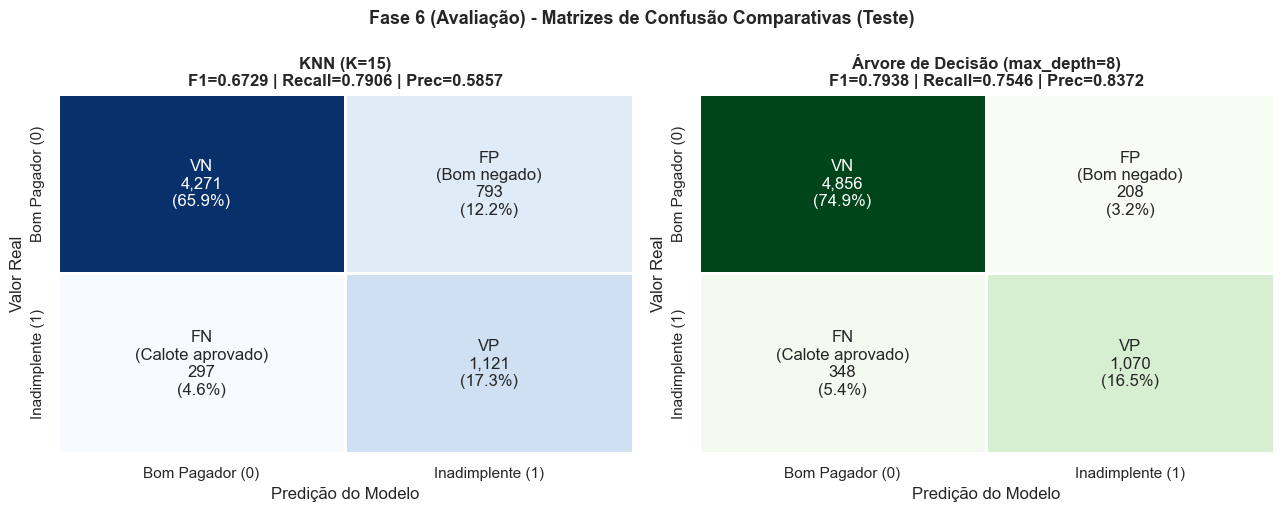

--- Top 10 Variáveis Mais Importantes (Árvore Vencedora) ---


,feature,importance,importance_pct
0,loan_grade,0.3503,35.0300
1,comprometimento_renda,0.2885,28.8500
2,person_income,0.1560,15.6000
3,person_home_ownership_RENT,0.0655,6.5500
4,person_home_ownership_OWN,0.0290,2.9000
5,loan_intent_HOMEIMPROVEMENT,0.0190,1.9000
6,loan_intent_VENTURE,0.0165,1.6500
7,loan_intent_MEDICAL,0.0146,1.4600
8,loan_intent_EDUCATION,0.0126,1.2600
9,loan_intent_PERSONAL,0.0107,1.0700


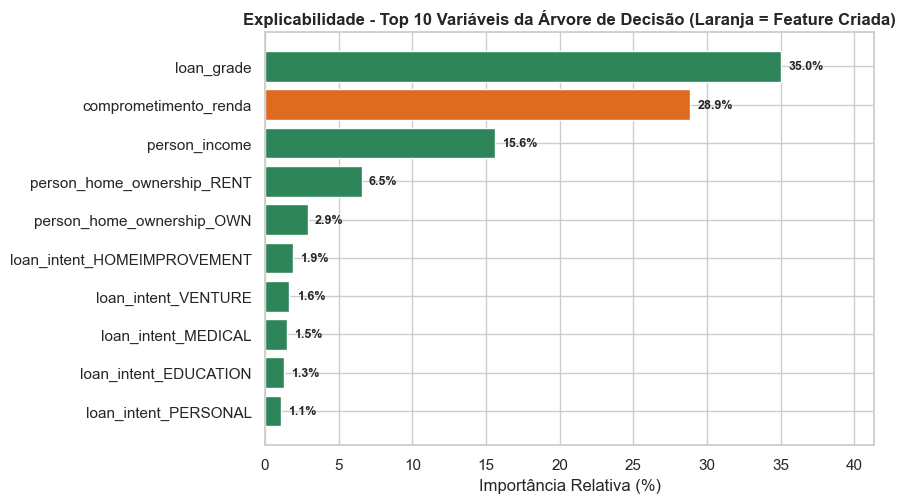

Premissas financeiras da base: Ticket médio = US$ 9,592.49 | Juros médios = 11.02% a.a. | LGD = 60%


,threshold,accuracy,precision,recall,f1,fp,fn,total_loss_usd
0,0.2000,0.7251,0.4370,0.8900,0.5862,1626,156,"2,616,235.9256"
1,0.3000,0.7650,0.4796,0.8717,0.6188,1341,182,"2,464,686.7956"
2,0.4000,0.8561,0.6346,0.8061,0.7102,658,275,"2,278,143.7525"
3,0.4500,0.9056,0.7937,0.7680,0.7806,283,329,"2,192,635.1599"
4,0.5000,0.9131,0.8327,0.7546,0.7917,215,348,"2,230,126.1721"
5,0.5500,0.9142,0.8372,0.7546,0.7938,208,348,"2,222,728.4757"
6,0.6000,0.9161,0.8496,0.7489,0.7961,188,356,"2,247,636.1365"
7,0.7000,0.9202,0.8751,0.7412,0.8026,150,367,"2,270,787.6255"


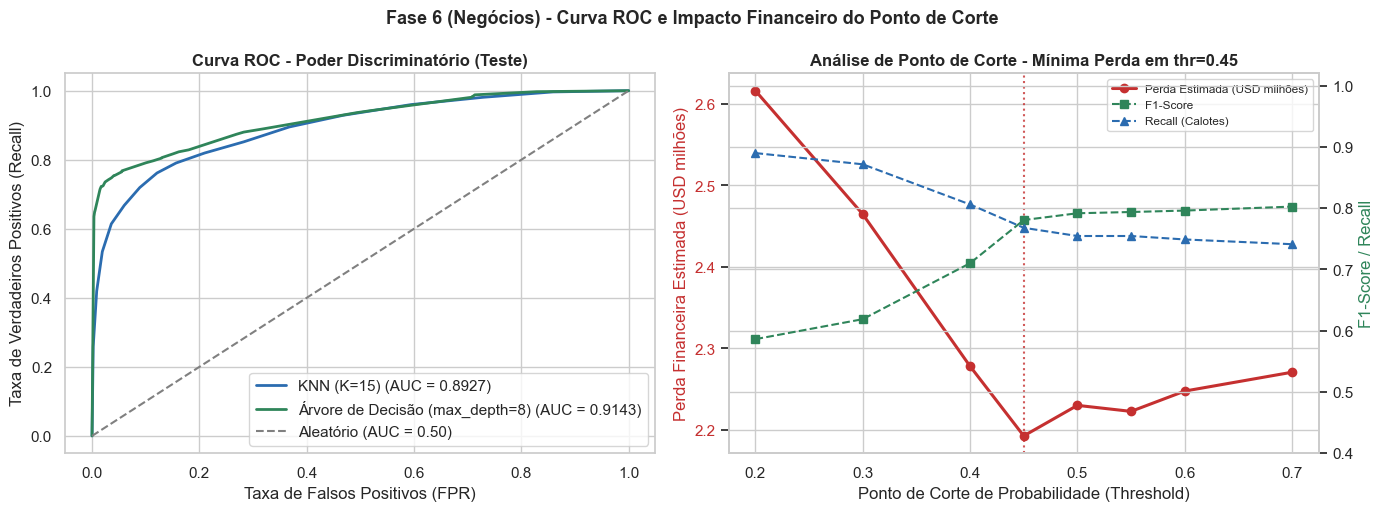

,Modelo,Acurácia,Precisão (Calote),Recall (Calote),F1-Score,ROC-AUC,FP (Bons Negados),FN (Calotes Aprovados),Perda Estimada FP (USD),Perda Estimada FN (USD),Impacto Total Estimado (USD)
0,KNN (K=15),0.8318,0.5857,0.7906,0.6729,0.8927,793,297,"838,053.3121","1,709,381.1219","2,547,434.4340"
1,Árvore de Decisão (max_depth=8),0.9142,0.8372,0.7546,0.7938,0.9143,208,348,"219,817.2622","2,002,911.2136","2,222,728.4757"


In [8]:
best_knn_model, best_knn_row = select_best_model(knn_df, knn_models, key_col="param_value")
best_tree_model, best_tree_row = select_best_model(tree_df, tree_models, key_col="param_label")

knn_eval = build_final_evaluation(
    best_knn_model,
    bundle["X_test_knn"],
    bundle["y_test"],
    f"KNN ({best_knn_row['param_label']})",
)
tree_eval = build_final_evaluation(
    best_tree_model,
    bundle["X_test_tree"],
    bundle["y_test"],
    f"Árvore de Decisão (max_depth={best_tree_row['param_label']})",
)

print(f"=== Classification Report - {knn_eval['model_name']} ===")
print(knn_eval["classification_report_text"])

print(f"=== Classification Report - {tree_eval['model_name']} ===")
print(tree_eval["classification_report_text"])

fig6 = plot_confusion_matrices(knn_eval, tree_eval, FIGURES_DIR / "06_matrizes_confusao_comparacao.png")
plt.show()

fi_df = extract_feature_importance(best_tree_model, bundle["feature_names"])
print("--- Top 10 Variáveis Mais Importantes (Árvore Vencedora) ---")
display(fi_df.head(10))
fig7 = plot_feature_importance(fi_df, save_path=FIGURES_DIR / "07_feature_importance_arvore.png")
plt.show()

ticket_medio = float(df_clean["loan_amnt"].mean())
taxa_juros_media = float(df_clean["loan_int_rate"].mean() / 100.0)
custo_fn = ticket_medio * DEFAULT_LGD
custo_fp = ticket_medio * taxa_juros_media

thr_df = evaluate_thresholds(
    best_tree_model,
    bundle["X_test_tree"],
    bundle["y_test"],
    ticket_medio=ticket_medio,
    taxa_juros_media=taxa_juros_media,
    lgd=DEFAULT_LGD,
)
print(f"Premissas financeiras da base: Ticket médio = US$ {ticket_medio:,.2f} | Juros médios = {taxa_juros_media*100:.2f}% a.a. | LGD = {DEFAULT_LGD*100:.0f}%")
display(thr_df[["threshold", "accuracy", "precision", "recall", "f1", "fp", "fn", "total_loss_usd"]])

fig8 = plot_roc_and_threshold(knn_eval, tree_eval, thr_df, FIGURES_DIR / "08_roc_e_ponto_de_corte.png")
plt.show()

comparativo_negocio = pd.DataFrame([
    {
        "Modelo": ev["model_name"],
        "Acurácia": ev["accuracy"],
        "Precisão (Calote)": ev["precision"],
        "Recall (Calote)": ev["recall"],
        "F1-Score": ev["f1"],
        "ROC-AUC": ev["roc_auc"],
        "FP (Bons Negados)": ev["fp"],
        "FN (Calotes Aprovados)": ev["fn"],
        "Perda Estimada FP (USD)": ev["fp"] * custo_fp,
        "Perda Estimada FN (USD)": ev["fn"] * custo_fn,
        "Impacto Total Estimado (USD)": ev["fp"] * custo_fp + ev["fn"] * custo_fn,
    }
    for ev in [knn_eval, tree_eval]
])
display(comparativo_negocio)

### Análise de Negócio e Veredito Final para Produção

#### 1. Qual erro pesa mais financeiramente para o banco?
- **Falso Negativo (FN - Mau pagador classificado como "Seguro")** é o erro mais caro por operação: o banco empresta o valor principal (ticket médio de **US\$ 9.592,49**) e arca com prejuízo direto (~**US\$ 5.755** por calote considerando perda líquida de 60% / LGD), somado a custos de cobrança e provisão regulatória (PDD).
- **Falso Positivo (FP - Bom pagador classificado como "Risco de Calote")** traz **custo de oportunidade** (~**US\$ 1.057** de juros anuais que deixam de entrar) e perda comercial de clientes. Quando ocorre em volume alto demais, compromete a receita e o crescimento da carteira.

#### 2. Comparação nas Matrizes de Confusão (`6.482` clientes de teste)
- **KNN (`K = 15`)**: bloqueou `1.121` inadimplentes (`Recall = 79,06%`, `297` FNs), mas negou crédito a **793 bons pagadores** (`FPR = 15,66%`, `Precisão = 58,57%`, perda total estimada em **US\$ 2,55 milhões**).
- **Árvore de Decisão (`max_depth = 8`)**: bloqueou `1.070` inadimplentes (`Recall = 75,46%`, `348` FNs) e baixou os Falsos Positivos para apenas **208 bons pagadores** (`FPR = 4,11%`, `Precisão = 83,72%`). São **585 bons clientes preservados** frente ao KNN, baixando a perda total estimada para **US\$ 2,22 milhões** (**~US\$ 325 mil de economia** na carteira de teste).
- **Ajuste do Ponto de Corte (*Threshold*)**: reduzindo o limiar da Árvore de `0,50` para **`0,45`**, o Recall sobe para **`76,80%`** (`19` calotes extras barrados: `329` FNs vs `348`) com apenas `283` FPs (`Precisão = 79,37%`, `Acurácia = 90,56%`), atingindo a **menor perda estimada: US\$ 2,19 milhões** (**~US\$ 355 mil abaixo do KNN**).

#### 3. Explicabilidade das Variáveis
No ranking de importância da Árvore vencedora, `loan_grade` (`35,0%`) e a coluna calculada **`comprometimento_renda` (`28,9%`)** respondem juntas por **63,9%** das decisões do modelo, confirmando o ganho real da Fase 3.

#### 4. Veredito Final: **Árvore de Decisão (`max_depth = 8`) em Produção** (ponto de corte em `0,45`)
A recomendação para produção é a **Árvore de Decisão (`max_depth = 8`)** pelos motivos abaixo:
1. **Melhor desempenho técnico**: supera o KNN em **F1-Score (`0,7938` vs `0,6729`)**, **Acurácia (`91,42%` vs `83,18%`)**, **Precisão (`83,72%` vs `58,57%`)**, **ROC-AUC (`0,9143` vs `0,8927`)**, **5-Fold CV (`0,7863 +/- 0,0065` vs `0,6607 +/- 0,0037`)** e **menor overfitting (`gap_f1 = 0,0495` vs `0,1540`)**.
2. **Menor perda financeira esperada**: economiza **~US\$ 325 mil** no corte padrão (`0,50`/`0,55`) e até **~US\$ 355 mil** calibrando o *threshold* para **`0,45`**.
3. **Operação rápida e transparente**: avalia novos clientes em até **8 comparações simples** (sem precisar guardar a base inteira para calcular distâncias como o KNN) e permite justificar claramente qualquer negativa de crédito para o cliente e para auditorias.